# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Alice Miller, Emma Crawford, Nina Beadnell, Maciek Romanowski**

## Setup

In [3]:
# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay, 
    ConfusionMatrixDisplay, roc_auc_score, average_precision_score, accuracy_score, precision_score, 
    recall_score, f1_score, silhouette_score, silhouette_samples)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (AgglomerativeClustering, KMeans)
from scipy.cluster.hierarchy import (linkage, dendrogram, fcluster)
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

# For feature engineering
from numpy.lib.stride_tricks import sliding_window_view

In [4]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

This report investigates daily river water levels recorded at 392 monitoring stations across 35 counties in Scotland between 2014 and 2026. Using supervised and unsupervised machine learning techniques, we aim to identify meaningful patterns in river behaviour and investigate the potential for predicting flood events.

The data used in this report contains the river level monitoring stations (by name and by ID label), their geographical location (county of Scotland, as well as longitude and latitude) and the reported daily average, minimum and maximum water levels (in metres).

Two objectives are considered. First, clustering is used to group monitoring stations according to similarities in their water-level characteristics. Second, binary classification is used to predict whether a station will experience a flood based on observations from the preceding seven days.

Before modelling, we analyse the data for missing observations, outliers and differences in station coverage. Relevant features are then constructed to describe river properties and aid further analysis.

First, we consider clustering, an unsupervised machine learning task where, based on the constructed features, we try to group together stations with similar properties. Clustering is crucial in identifying trends, patterns and intrinsic relationships in the dataset. We implement the K-means++ and hierarchical clustering algorithms and compare their performance. We observe that all stations can be grouped into three separate groups: one containing all of the tidal stations, [input rest].

Second, we consider classification, a supervised machine learning task, where we aim to build a model to predict future flood events. We train and test various models to find the one with the best performance. Given that flood events are rare, we choose as a baseline a model which always predicts no flood. Our best performing model is [insert model].

Building on our classification model, we identify factors that can be used to predict flood events. These findings can help government agencies understand river behaviour and identify regions at high risk of flooding. By predicting floods before they occur, we aim to ease the strain on government and emergency services, and reduce the human cost of flooding [reference 1].

# Exploratory Data Analysis and Feature Engineering

##  Exploratory Data Analysis
- Missing values plot
- Report on 'abnormal values'
- Apply all findings via `data_prepare` function

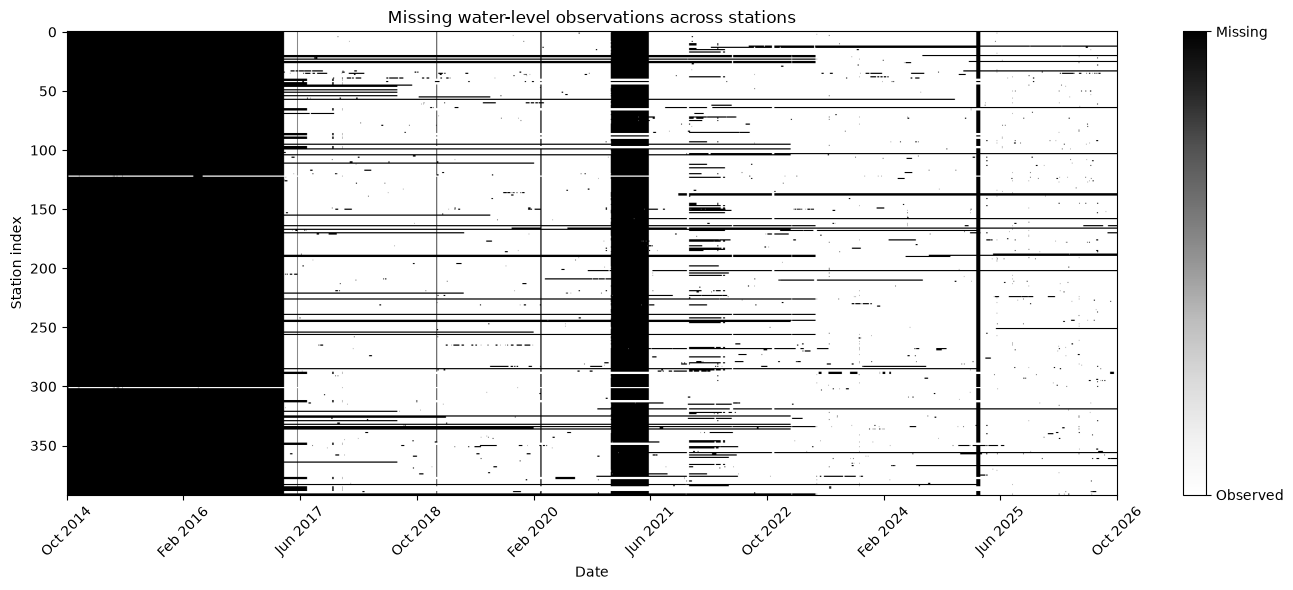

In [5]:
# Investigating the missing observations across different stations

# Select date columns
date_cols = df_avg.columns[3:]

data = df_avg[date_cols].apply(pd.to_numeric, errors="coerce")  # Make sure that the data has numerical values or NaN for missing values

# Convert columns to dates
data.columns = pd.to_datetime(date_cols, dayfirst=True)

# Insert missing dates
all_dates = pd.date_range(start=data.columns.min(), end=data.columns.max(), freq="D")

# If the date does NOT exist pandas creates a new column filled with NaN
data = data.reindex(columns=all_dates)

# Missing-data matrix: 1 = missing, 0 = observed
missing = data.isna().astype(int)

# Plot a heatmap
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(missing, aspect="auto", cmap="Greys")

# Date labels
ticks = np.linspace(0, len(all_dates) - 1, 10, dtype=int)

# Set labels, ticks, and title
ax.set_xticks(ticks)
ax.set_xticklabels(all_dates[ticks].strftime("%b %Y"), rotation=45)

ax.set_xlabel("Date")
ax.set_ylabel("Station index")
ax.set_title("Missing water-level observations across stations")

# Colourbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Observed", "Missing"])

plt.tight_layout()
plt.show()

In [6]:
results = []

for name, df in {
    "Average": df_avg,
    "Maximum": df_max,
    "Minimum": df_min
}.items():

    data = df.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

    n_outliers = (data.abs() > 30).sum().sum()
    n_observations = data.count().sum()

    results.append({
        "Dataset": name,
        "Observations": n_observations,
        "Abnormal observations": n_outliers,
        "Percentage (%)": 100 * n_outliers / n_observations
    })

display(pd.DataFrame(results).round(4).set_index("Dataset"))

# Frequency of abnormal values in the average dataset
data = df_avg.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

display(
    data.where(data.abs() > 36).stack().value_counts()
    .rename_axis("Abnormal value")
    .to_frame("Frequency")
)

,Observations,Abnormal observations,Percentage (%)
Dataset,,,
Average,1190691,929,0.0780
Maximum,1190691,979,0.0822
Minimum,1190691,759,0.0637


,Frequency
Abnormal value,
98.070,1
170.415,1
192.294,1
20833.839,1
20833.901,1
...,...
21740.183,1
11905.747,1
21979.385,1


In [7]:
# Data preprocessing
def data_prepare(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(pd.to_numeric, errors="coerce")

    # Replace observations with |value| > 30 with NaN
    data = data.mask(data.abs() > 36)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(start=data.columns.min(), end=data.columns.max(), freq="D")

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = data_prepare(df_avg)
minimum = data_prepare(df_min)
maximum = data_prepare(df_max)

## Clustering
- Outline approach

### Feature engineering for Clustering problem
- Features selected: IQR, Upper_tail, Daily_range, Daily_change, Autocorr_1, Seasonality, Lower_tail
- Explain reasoning beyond feature selection in context of target audience


In [8]:
# Define the features we want to use for the clustering problem 

# Interquartile range
iqr = avg.quantile(0.75) - avg.quantile(0.25)

# Upper-tail intensity
tail = ((avg.quantile(0.99) - avg.quantile(0.50)) / iqr.where(iqr > 1e-8))

# Lower-tail intensity
tail_l = ((avg.quantile(0.50) - avg.quantile(0.01)) / iqr.where(iqr > 1e-8))

# Within-day variability (where to account for possible NaN values)
daily_range = (maximum - minimum).where(maximum >= minimum)
R = daily_range.median()

# Daily changes
D = avg.diff().abs().median()

# Daily qutocorrelation
A1 = avg.corrwith(avg.shift(1))

# Seasonal variation
first_half = avg[avg.index.month.isin([1, 2, 3, 4, 5, 6])].median()
second_half = avg[avg.index.month.isin([7, 8, 9, 10, 11, 12])].median()

S = first_half - second_half

# Construct feature matrix
X_cluster = pd.DataFrame({
    "IQR": iqr,
    "Upper_tail": tail,
    "Daily_range": R,
    "Daily_change": D,
    "Autocorr_1": A1,
    "Seasonality": S,
    "Lower_tail": tail_l
})

### Clustering and Outcomes

- Present silhouette plots
- Explain number of clusters selected
- Explain what has been found as result of clustering process

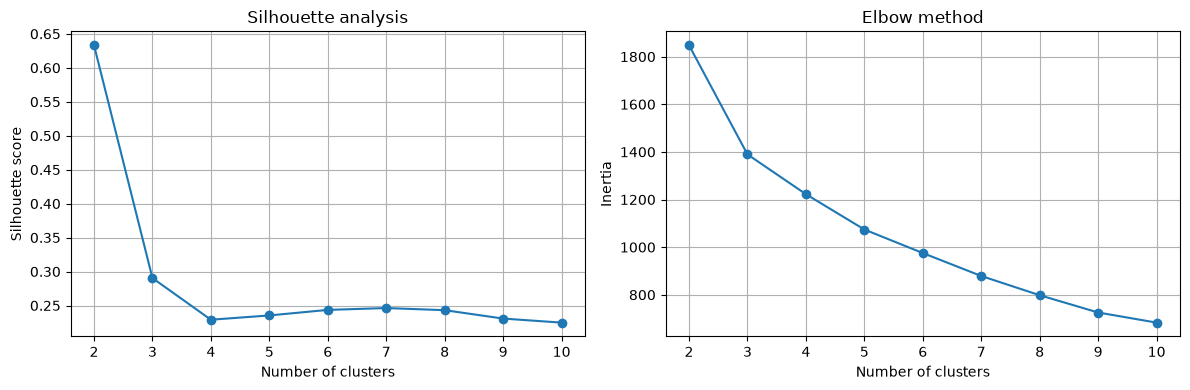

In [9]:
# Creating the pipeline and investigating the number of clusters

k_values = range(2, 11)

silhouette_scores = []
inertias = []

for k in k_values:

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=42
        ))
    ])

    labels = pipeline.fit_predict(X_cluster)

    X_scaled = pipeline.named_steps["scaler"].transform(X_cluster)

    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

    inertias.append(
        pipeline.named_steps["kmeans"].inertia_
    )


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, silhouette_scores, marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Silhouette score")
axes[0].set_title("Silhouette analysis")

axes[1].plot(k_values, inertias, marker="o")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Inertia")
axes[1].set_title("Elbow method")

for ax in axes:
    ax.grid()

plt.tight_layout()
plt.show()

In [10]:
# Building a model with 3 clusters
pipeline3 = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=20,
        random_state=42
    ))
])

labels3 = pipeline3.fit_predict(X_cluster)

X_clustered3 = X_cluster.copy()
X_clustered3["Cluster"] = labels3

In [11]:
# Cluster sizes and median feature values
summary = X_clustered3.groupby("Cluster").median().round(3)
summary.insert(0, "Stations", X_clustered3.groupby("Cluster").size())

display(summary)

# Identify tidal stations
results = df_avg.loc[X_clustered3.index, ["Observation_ID"]].copy()

results["Cluster"] = X_clustered3["Cluster"]

results["Tidal"] = results["Observation_ID"].str.contains(
    "tidal-level", case=False, na=False
)

display(pd.crosstab(results["Cluster"], results["Tidal"]))

,Stations,IQR,Upper_tail,Daily_range,Daily_change,Autocorr_1,Seasonality,Lower_tail
Cluster,,,,,,,,
0,224,0.186,3.433,0.025,0.016,0.834,-0.003,0.860
1,20,0.292,4.016,2.874,0.107,0.531,-0.064,3.962
2,148,0.365,2.683,0.069,0.043,0.824,-0.064,0.864


Tidal,False,True
Cluster,,
0,224,0
1,10,10
2,146,2


## Feature engineering for Classification problem
- Features selected:
- Test-train split with reasoning

In [12]:
# Keep only 8-day windows where avg, min, and max all have no missing values
valid = avg.notna() & minimum.notna() & maximum.notna()
valid_8 = valid.rolling(8, min_periods=8).sum().eq(8)

# Find the date where 80% of valid windows have occurred (chronological 80/20 split)
total_valid = valid_8.sum().sum()
split = (valid_8.sum(axis=1).cumsum() >= 0.8 * total_valid).argmax() + 1

# Define floods as > 99th percentile of max water level
thresholds = maximum.iloc[:split].quantile(0.99).dropna()
flood = maximum[thresholds.index] > thresholds
valid_flood = flood.where(valid_8[thresholds.index])

y_train = valid_flood.iloc[:split].stack().dropna().astype(int)
y_test = valid_flood.iloc[split:].stack().dropna().astype(int)

# Standardise each station (Z-Score)
feat_source = maximum[thresholds.index]
station_mean = feat_source.iloc[:split].mean()
station_std = feat_source.iloc[:split].std().fillna(0) + 1e-8
feat_z = (feat_source - station_mean) / station_std

X_train_z = pd.DataFrame()
X_test_z = pd.DataFrame()

mask = valid_8[thresholds.index]

# Makes 7 separate columns: Day 1 (7 days ago) ... Day 7 (yesterday)
for i in range(1, 8):
    lag = 8 - i  # Day 1 is 7 days ago (lag=7) ... Day 7 is yesterday (lag=1)
    shifted = feat_z.shift(lag).where(mask)
    
    X_train_z[f"Day {i}"] = shifted.iloc[:split].stack().dropna()
    X_test_z[f"Day {i}"] = shifted.iloc[split:].stack().dropna()

# Model Fitting and Tuning

Outline approach

## Classification
### Baseline Model
- Introduce interpretable baseline model of our choice 

In [15]:
### MACIEK ####
# Baseline model 

### Selected Classification Model
- Present model
- Why we chose this against any other model

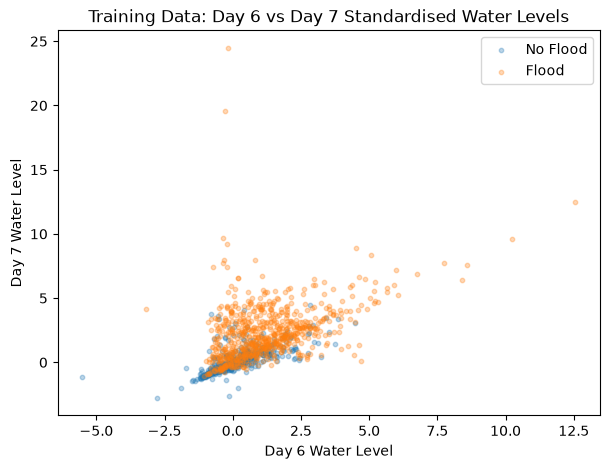

In [19]:
### REMOE IF TOO LONG ###
# Sample 700 non-flood days and 700 flood days from training so the plot is readable
no_flood_sample = X_train_z[y_train == 0].sample(700, random_state=1)
flood_sample = X_train_z[y_train == 1].sample(700, random_state=1)

plt.figure(figsize=(7, 5))
plt.scatter(no_flood_sample["Day 6"], no_flood_sample["Day 7"], alpha=0.3, s=10, label="No Flood")
plt.scatter(flood_sample["Day 6"], flood_sample["Day 7"], alpha=0.3, s=10, label="Flood")
plt.xlabel("Day 6 Water Level")
plt.ylabel("Day 7 Water Level")
plt.title("Training Data: Day 6 vs Day 7 Standardised Water Levels")
plt.legend()
plt.show()

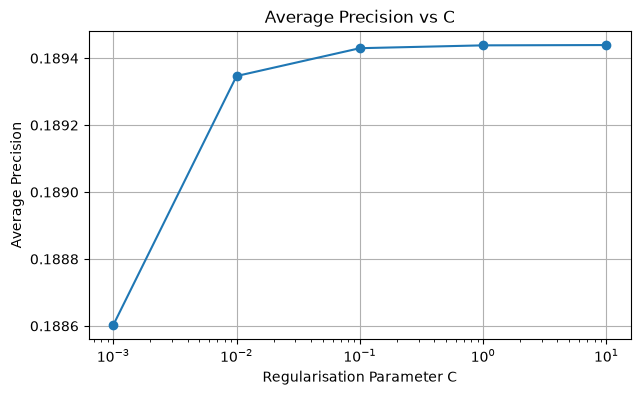

In [20]:
# Tune C on X_train_z using chronological 3-fold cross-validation
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=3)
C_values = [0.001, 0.01, 0.1, 1.0, 10.0]
mean_ap_scores = []

for c in C_values:
    svc = LinearSVC(C=c, random_state=1, max_iter=5000)
    scores = cross_val_score(svc, X_train_z, y_train, cv=tscv, scoring="average_precision")
    mean_ap_scores.append(scores.mean())

plt.figure(figsize=(7, 4))
plt.plot(C_values, mean_ap_scores, marker="o")
plt.xscale("log")
plt.xlabel("Regularisation Parameter C")
plt.ylabel("Average Precision")
plt.title("Average Precision vs C")
plt.grid(True)
plt.show()

,Threshold,Recall,Precision,F1-Score,Floods Predicted
0,0.01,0.7603,0.0694,0.1272,33136
5,0.10,0.3135,0.3716,0.3401,2551
8,0.50,0.0678,0.6156,0.1221,333


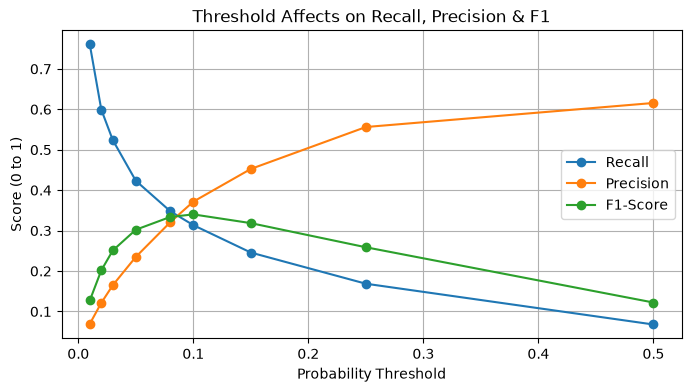

In [24]:
# Validation on 20% of training dat
val_cut = int(0.8 * len(X_train_z))
X_tr, y_tr = X_train_z.iloc[:val_cut], y_train.iloc[:val_cut]
X_val, y_val = X_train_z.iloc[val_cut:], y_train.iloc[val_cut:]

# Fit LinearSVC (C=0.1) with Platt scaling
val_svc = CalibratedClassifierCV(
    LinearSVC(C=0.1, random_state=1, max_iter=5000),
    method="sigmoid",
    cv=3,
    ensemble=False
)
val_svc.fit(X_tr, y_tr)

# Test different probability thresholds on the validation set
test_thresholds = [0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.25, 0.50]
rows = []

# validation probabilities and candidate thresholds
val_probs = val_svc.predict_proba(X_val)[:, 1]
prec, rec, thresh = precision_recall_curve(y_val, val_probs)
f1_scores = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)

best_f1_thresh = thresh[np.argmax(f1_scores)]

for t in test_thresholds:
    preds = (val_probs >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Recall": recall_score(y_val, preds),
        "Precision": precision_score(y_val, preds, zero_division=0),
        "F1-Score": f1_score(y_val, preds),
        "Floods Predicted": preds.sum()
    })

thresh_df = pd.DataFrame(rows)
display(thresh_df.iloc[[0, 5, 8]].round(4))

# Plot recall, Precision, and F1 for each threshold
plt.figure(figsize=(8, 4))
plt.plot(thresh_df["Threshold"], thresh_df["Recall"], marker="o", label="Recall")
plt.plot(thresh_df["Threshold"], thresh_df["Precision"], marker="o", label="Precision")
plt.plot(thresh_df["Threshold"], thresh_df["F1-Score"], marker="o", label="F1-Score")
plt.xlabel("Probability Threshold")
plt.ylabel("Score (0 to 1)")
plt.title("Threshold Affects on Recall, Precision & F1")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
# Refit the final calibrated model on all training data
final_svc = CalibratedClassifierCV(
    LinearSVC(C=0.1, random_state=1, max_iter=5000),
    method="sigmoid",
    cv=3,
    ensemble=False
)
final_svc.fit(X_train_z, y_train)

# Predict flood probabilities on the test set
y_probs = final_svc.predict_proba(X_test_z)[:, 1]

# Interpretation, Discussion & Conclusions

- What Drives Flood Predictions (Feature Interpretation)
- Practicalities
- Limitations 


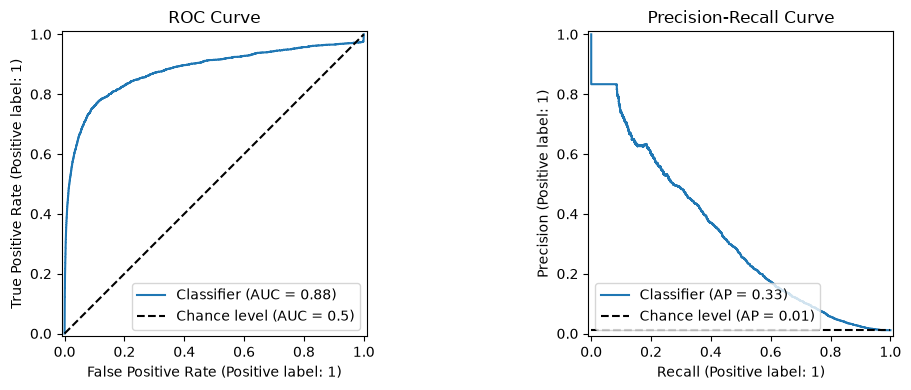

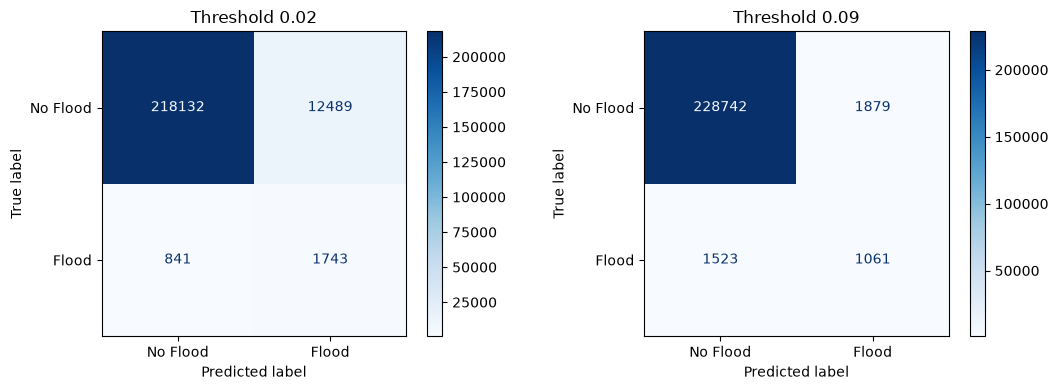

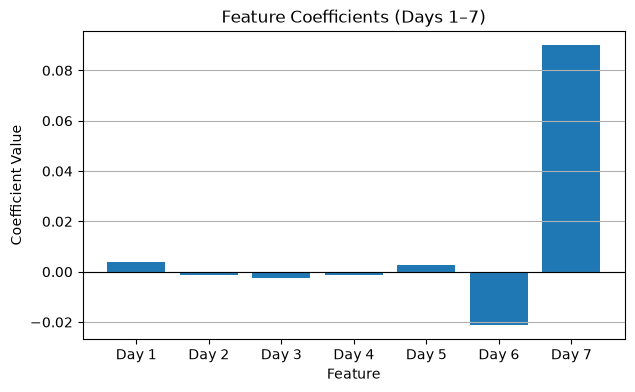

In [26]:
### NOTE: remove if too long, tidy up labels
# Plot ROC Curve and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_test, y_probs, plot_chance_level=True, ax=axes[0])
axes[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(y_test, y_probs, plot_chance_level=True, ax=axes[1])
axes[1].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

# Plot Confusion Matrices side-by-side (0.03 vs 0.09)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, (y_probs >= 0.02).astype(int),
    display_labels=["No Flood", "Flood"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Threshold 0.02")

ConfusionMatrixDisplay.from_predictions(
    y_test, (y_probs >= 0.09).astype(int),
    display_labels=["No Flood", "Flood"], cmap="Blues", ax=axes[1]
)
axes[1].set_title("Threshold 0.09")
plt.tight_layout()
plt.show()

# Plot the 7 Feature Coefficients (matching Week 7 Workshop Exercise 10b)
weights = final_svc.calibrated_classifiers_[0].estimator.coef_[0]
coef_df = pd.DataFrame({"Day": X_train_z.columns, "Coefficient": weights})

plt.figure(figsize=(7, 4))
plt.bar(coef_df["Day"], coef_df["Coefficient"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Feature Coefficients (Days 1–7)")
plt.xlabel("Feature")
plt.ylabel("Coefficient Value")
plt.grid(axis="y")
plt.show()

# Generative AI statement

Generative AI was used in this project in following ways:
- Told us how to make citable references in Jupyter Notebook
- Debug code and help with error messages
- Suggest code improvements, and ways to make it cleaner and faster
- Improve the presentation of the plots 
- Turn the code outputs into neat tables 

# References

<a id="ref1"></a>
[1] Scottish Government (2026). 
*National Flood Resilience Strategy: Implementation Plan*.
[Available online](https://www.gov.scot/publications/national-flood-resilience-strategy-implementation-plan/pages/2/).

<a id="ref2"></a>
[2] Sell, T. (2026). *Machine Learning in Python: 
Week 1 – Introduction to Machine Learning and Feature Engineering*. 
Lecture notes, School of Mathematics, University of Edinburgh.

<a id="ref3"></a>
[3] pandas development team (n.d.). 
*Time series / date functionality*. pandas documentation.
[Available online](https://pandas.pydata.org/docs/user_guide/timeseries.html).
(Accessed: 24 November 2026).

<a id="ref4"></a>
[4] Met Office (n.d.). *Charterhall: Location-specific long-term 
averages (1991–2020)*. 
[Available online](https://www.metoffice.gov.uk/research/climate/maps-and-data/location-specific-long-term-averages/gcykcv8b2).
(Accessed: 25 November 2026).

[1] - https://audit.scot/uploads/2025-08/nr_250828_flooding_in_communities.pdf, ISBN 978 1 915839 80 0, AGS/2025/6

In [1]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Writing 29863 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 47131 bytes to project.pdf
